In [ ]:
import os
import pandas as pd
import numpy as np
from matplotlib.colors import ListedColormap
import torch
import evaluate
import rasterio
from oauthlib.oauth2 import BackendApplicationClient
from requests_oauthlib import OAuth2Session
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from transformers import SegformerForSemanticSegmentation
from peft import PeftModel
from Data_Loader import Sen1Floods11Dataset

## Test Set

In [ ]:
sen1floods11_data_folder = "../Data/Sen1Floods11/"
splits = sen1floods11_data_folder + "splits/"
SAR_data  = sen1floods11_data_folder + "S1Hand/"
Label_data = sen1floods11_data_folder + "LabelHand/"

test_files = pd.read_csv(splits + 'flood_test_data.csv',header=None, names=["SAR", "Label"])
test_dataset = Sen1Floods11Dataset(SAR_data, Label_data, test_files)

In [ ]:
model_dir = "../Models/Focal_Dice"
model = SegformerForSemanticSegmentation.from_pretrained(model_dir)
model.eval()
model.to("cuda")

test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)
metric = evaluate.load("mean_iou")
all_predicted_masks = {}

for idx,batch in enumerate(test_loader):
    pixel_values = batch["pixel_values"].to("cuda")
    labels = batch["labels"].numpy()

    with torch.no_grad():
        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits

        upsampled_logits = torch.nn.functional.interpolate(
            logits, size=(512, 512), mode="bilinear", align_corners=False)
        predictions = upsampled_logits.argmax(dim=1).squeeze().cpu().numpy()
        all_predicted_masks[idx] = predictions
        metric.add_batch(predictions=np.expand_dims(predictions, axis=0), references=labels)

final_metrics = metric.compute(num_labels=2, ignore_index=255, reduce_labels=False)

print(f"Global Pixel Accuracy: {final_metrics['mean_accuracy']*100:.2f}%")
print(f"Mean IoU (mIoU): {final_metrics['mean_iou']*100:.2f}%")
print(f"Land Class IoU: {final_metrics['per_category_iou'][0]*100:.2f}%")
print(f"Flood Water Class IoU: {final_metrics['per_category_iou'][1]*100:.2f}%")

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/datasets/features/image.py:406: UserWarning: Downcasting array dtype int64 to int32 to be compatible with 'Pillow'
  warnings.warn(f"Downcasting array dtype {dtype} to {dest_dtype} to be compatible with 'Pillow'")


Global Pixel Accuracy: 87.93%
Mean IoU (mIoU): 78.58%
Land Class IoU: 93.66%
Flood Water Class IoU: 63.50%


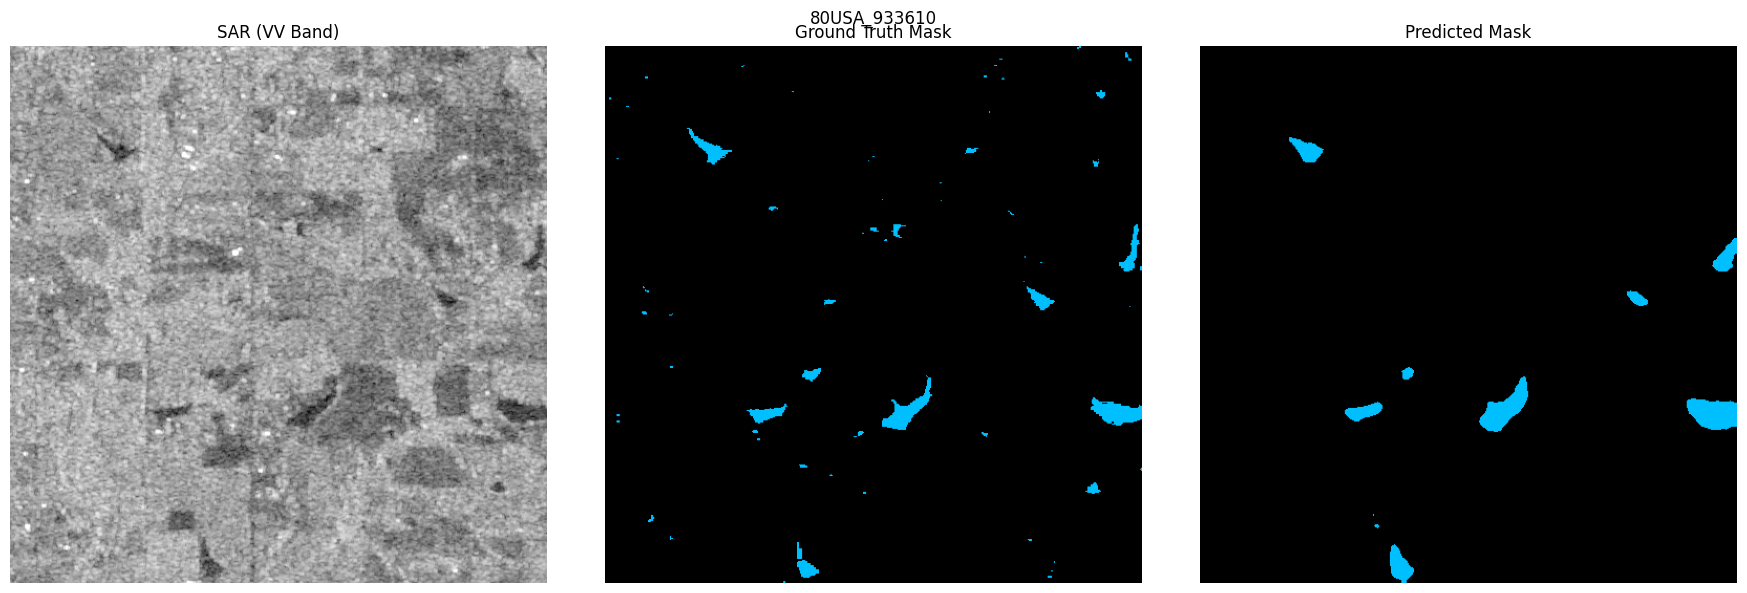

In [ ]:
# 90 flood images in test set

i = 80
flood_name = test_files['SAR'].iloc[i].rsplit('_S1Hand.tif',1)[0]

flood_point = test_dataset[i]
vv_sar = (flood_point["pixel_values"][0].numpy() * 255).astype(np.uint8)
vh_sar = (flood_point["pixel_values"][1].numpy() * 255).astype(np.uint8)
ground_truth = flood_point["labels"].numpy()
predicted = all_predicted_masks[i]


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(str(i)+flood_name)

axes[0].imshow(vv_sar, cmap='gray')
axes[0].set_title("SAR (VV Band)")
axes[0].axis('off')

shown_mask = np.ma.masked_where(ground_truth == -1, ground_truth)
cmap = ListedColormap(["black", "deepskyblue"])
cmap.set_bad("lightgray")

axes[1].imshow(ground_truth, cmap=cmap, vmin=0, vmax=1)
axes[1].set_title("Ground Truth Mask")
axes[1].axis('off')

axes[2].imshow(predicted, cmap=cmap, vmin=0, vmax=1)
axes[2].set_title("Predicted Mask")
axes[2].axis('off')

plt.tight_layout()
#plt.savefig(str(i)+"_"+flood_name+'.jpg')
plt.show()

## Valencia

In [119]:
bbox_1 = [-0.5856698909927794,
        39.4542717707340387,
        -0.5245790530522754,
        39.5016152417541306]

bbox_2 = [-0.5262131856583661,
          39.4529912100614126,
          -0.4650869237410651,
          39.5003630028981831]

bbox_3 = [-0.5278435701465212,
          39.4069016394871028,
          -0.4667602284359437,
          39.4542717707340387]

In [ ]:
#Getting the Sentinel 1 SAR data for the relevant Valencia bbox(es)

client_id = 'sh-63a9a4f4-1d8a-4520-8bde-219033d8a61f'
client_secret = 'yCRMcZylk2ngArIX4x8a75ke7V9UmnIHw69wBrxjEaI4h2zBA3h7erMpVYB6SGwEJl6OL7R0NfyO5gnHT12Esa'

client = BackendApplicationClient(client_id=client_id)
oauth = OAuth2Session(client=client)

token = oauth.fetch_token(token_url='https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token',
                          client_secret=client_secret, include_client_id=True)

resp = oauth.get("https://sh.dataspace.copernicus.eu/configuration/v1/wms/instances")
print(resp.content)

def sentinelhub_compliance_hook(response):
    response.raise_for_status()
    return response

oauth.register_compliance_hook("access_token_response", sentinelhub_compliance_hook)

b'<html>\n<head>\n<meta http-equiv="Content-Type" content="text/html;charset=utf-8"/>\n<title>Error 500 Request failed.</title>\n</head>\n<body><h2>HTTP ERROR 500 Request failed.</h2>\n<table>\n<tr><th>URI:</th><td>/configuration/v1/wms/instances</td></tr>\n<tr><th>STATUS:</th><td>500</td></tr>\n<tr><th>MESSAGE:</th><td>Request failed.</td></tr>\n<tr><th>SERVLET:</th><td>org.glassfish.jersey.servlet.ServletContainer-1bb172dd</td></tr>\n</table>\n\n</body>\n</html>\n'


In [121]:
evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["VV", "VH"],
    output: { id: "default", bands: 2, sampleType: "FLOAT32",},
  }
}

function evaluatePixel(samples) {
  var vvdB = 10 * Math.log10(samples.VV);
  var vhdB = 10 * Math.log10(samples.VH);
  return [vvdB, vhdB]
}
"""

request = {
    "input": {
        "bounds": {
            "bbox": {},
            "properties": {"crs": "http://www.opengis.net/def/crs/EPSG/0/4326"},
        },
        "data": [
            {
                "type": "sentinel-1-grd",
                "dataFilter": {
                    "timeRange": {},
                    "acquisitionMode": "IW",
                    "polarization": "DV",
                },
                "processing": {
                    "backCoeff": "GAMMA0_ELLIPSOID",
                    "orthorectify": "true",
                },
            }
        ],
    },
    "output": {
        "width": 512,
        "height": 512,
        "responses": [
            {
                "identifier": "default",
                "format": {"type": "image/tiff"},
            }
        ],
    },
    "evalscript": evalscript,
}

url = "https://sh.dataspace.copernicus.eu/process/v1"

In [ ]:
pre = {"from": "2024-10-19T00:00:00Z",
        "to": "2024-10-19T23:59:59Z",}

post = {"from": "2024-10-31T00:00:00Z",
        "to": "2024-10-31T23:59:59Z",}


for bi,b in enumerate([bbox_1,bbox_2,bbox_3]):
  for ti, t in enumerate([pre,post]):

      request["input"]["bounds"]["bbox"] = b
      request["input"]["data"][0]["dataFilter"]["timeRange"] = t

      response = oauth.post(url, json=request, headers={"Accept": "image/tiff"})

      if response.status_code == 200:
          if ti==0:
            state = "_Pre.tiff"
          else:
            state = "_Post.tiff"
          output_filename = "../Data/Valencia/Case_"+str(bi+1)+state

          with open(output_filename, "wb") as f:
              f.write(response.content)
          print(output_filename+" done.")

../Data/Valencia/Case_1_Pre.tiff done.
../Data/Valencia/Case_1_Post.tiff done.
../Data/Valencia/Case_2_Pre.tiff done.
../Data/Valencia/Case_2_Post.tiff done.
../Data/Valencia/Case_3_Pre.tiff done.
../Data/Valencia/Case_3_Post.tiff done.


### Model Testing

In [ ]:
valencia_data = "../Data/Valencia/"

# The ground truths ("..._Post_Label.tif") were obtained by rasterizing flood vector (CAMS Emergency Service) on QGIS
post_files = [("Case_1_Post.tiff","Case_1_Post_Label.tif"),
("Case_2_Post.tiff","Case_2_Post_Label.tif"),
("Case_3_Post.tiff","Case_3_Post_Label.tif")]

pre_files = [("Case_1_Pre.tiff","Case_1_Post_Label.tif"),
("Case_2_Pre.tiff","Case_2_Post_Label.tif"),
("Case_3_Pre.tiff","Case_3_Post_Label.tif")]

valencia_post_files = pd.DataFrame(post_files, columns=['SAR','Label'])
valencia_pre_files = pd.DataFrame(pre_files, columns=['SAR','Label'])

valencia_post_dataset = Sen1Floods11Dataset(valencia_data, valencia_data, valencia_post_files)
valencia_pre_dataset = Sen1Floods11Dataset(valencia_data, valencia_data, valencia_pre_files)

In [ ]:
model_dir = "../Models/Focal_Dice"
model = SegformerForSemanticSegmentation.from_pretrained(model_dir)
model.eval()
model.to("cuda")

post_loader = DataLoader(valencia_post_dataset, batch_size=1, shuffle=False)
metric = evaluate.load("mean_iou")
all_predicted_masks = {}

for idx,batch in enumerate(post_loader):
    pixel_values = batch["pixel_values"].to("cuda")
    labels = batch["labels"].numpy()

    with torch.no_grad():
        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits

        upsampled_logits = torch.nn.functional.interpolate(
            logits, size=(512, 512), mode="bilinear", align_corners=False)
        predictions = upsampled_logits.argmax(dim=1).squeeze().cpu().numpy()
        all_predicted_masks[idx] = predictions
        metric.add_batch(predictions=np.expand_dims(predictions, axis=0), references=labels)

final_metrics = metric.compute(num_labels=2, ignore_index=255, reduce_labels=False)

print(f"Global Pixel Accuracy: {final_metrics['mean_accuracy']*100:.2f}%")
print(f"Mean IoU (mIoU): {final_metrics['mean_iou']*100:.2f}%")
print(f"Land Class IoU: {final_metrics['per_category_iou'][0]*100:.2f}%")
print(f"Flood Water Class IoU: {final_metrics['per_category_iou'][1]*100:.2f}%")

In [ ]:
#Getting models predictions on sar readings pre-flood just for a baseline

all_predicted_masks_pre = {}

pre_loader = DataLoader(valencia_pre_dataset, batch_size=1, shuffle=False)

for idx,batch in enumerate(pre_loader):
    pixel_values = batch["pixel_values"].to("cuda")
    labels = batch["labels"].numpy()

    with torch.no_grad():
        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits

        upsampled_logits = torch.nn.functional.interpolate(
            logits, size=(512, 512), mode="bilinear", align_corners=False)
        predictions = upsampled_logits.argmax(dim=1).squeeze().cpu().numpy()
        all_predicted_masks_pre[idx] = predictions

In [ ]:
for i in range(3):

  flood_point = valencia_post_dataset[i]
  vv_sar = (flood_point["pixel_values"][0].numpy() * 255).astype(np.uint8)
  vh_sar = (flood_point["pixel_values"][1].numpy() * 255).astype(np.uint8)
  ground_truth = flood_point["labels"].numpy()
  predicted = all_predicted_masks[i]
  predicted_pre = all_predicted_masks_pre[i]


  fig, axes = plt.subplots(1, 4, figsize=(18, 6))

  axes[0].imshow(vv_sar, cmap='gray')
  axes[0].set_title("SAR (VV Band)")
  axes[0].axis('off')

  shown_mask = np.ma.masked_where(ground_truth == -1, ground_truth)
  cmap = ListedColormap(["black", "deepskyblue"])
  cmap.set_bad("lightgray")

  axes[1].imshow(ground_truth, cmap=cmap, vmin=0, vmax=1)
  axes[1].set_title("Ground Truth Mask")
  axes[1].axis('off')

  axes[2].imshow(predicted, cmap=cmap, vmin=0, vmax=1)
  axes[2].set_title("Predicted Mask")
  axes[2].axis('off')

  axes[3].imshow(predicted_pre, cmap=cmap, vmin=0, vmax=1)
  axes[3].set_title("Pre Flood Prediction Mask")
  axes[3].axis('off')

  plt.tight_layout()
  #plt.savefig(str(i)+"_"+flood_name+'.jpg')
  plt.show()

In [101]:
import gc
del model
gc.collect()
torch.cuda.empty_cache()

In [ ]:
model_id = "nvidia/segformer-b2-finetuned-ade-512-512"
dora = "/content/drive/MyDrive/Saved_models/DoRA_32"

model_base = SegformerForSemanticSegmentation.from_pretrained(
    model_id,
    num_labels=2,
    ignore_mismatched_sizes=True
)

model = PeftModel.from_pretrained(model_base, dora)

model.eval()
model.to("cuda")
print()

In [ ]:
post_loader = DataLoader(valencia_post_dataset, batch_size=1, shuffle=False)
metric = evaluate.load("mean_iou")
all_predicted_masks = {}

for idx,batch in enumerate(post_loader):
    pixel_values = batch["pixel_values"].to("cuda")
    labels = batch["labels"].numpy()

    with torch.no_grad():
        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits

        upsampled_logits = torch.nn.functional.interpolate(
            logits, size=(512, 512), mode="bilinear", align_corners=False)
        predictions = upsampled_logits.argmax(dim=1).squeeze().cpu().numpy()
        all_predicted_masks[idx] = predictions
        metric.add_batch(predictions=np.expand_dims(predictions, axis=0), references=labels)

final_metrics = metric.compute(num_labels=2, ignore_index=255, reduce_labels=False)

print(f"Global Pixel Accuracy: {final_metrics['mean_accuracy']*100:.2f}%")
print(f"Mean IoU (mIoU): {final_metrics['mean_iou']*100:.2f}%")
print(f"Land Class IoU: {final_metrics['per_category_iou'][0]*100:.2f}%")
print(f"Flood Water Class IoU: {final_metrics['per_category_iou'][1]*100:.2f}%")

In [ ]:
all_predicted_masks_pre = {}

pre_loader = DataLoader(valencia_pre_dataset, batch_size=1, shuffle=False)

for idx,batch in enumerate(pre_loader):
    pixel_values = batch["pixel_values"].to("cuda")
    labels = batch["labels"].numpy()

    with torch.no_grad():
        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits

        upsampled_logits = torch.nn.functional.interpolate(
            logits, size=(512, 512), mode="bilinear", align_corners=False)
        predictions = upsampled_logits.argmax(dim=1).squeeze().cpu().numpy()
        all_predicted_masks_pre[idx] = predictions

In [ ]:
for i in range(3):

  flood_point = valencia_post_dataset[i]
  vv_sar = (flood_point["pixel_values"][0].numpy() * 255).astype(np.uint8)
  vh_sar = (flood_point["pixel_values"][1].numpy() * 255).astype(np.uint8)
  ground_truth = flood_point["labels"].numpy()
  predicted = all_predicted_masks[i]
  predicted_pre = all_predicted_masks_pre[i]


  fig, axes = plt.subplots(1, 4, figsize=(18, 6))

  axes[0].imshow(vv_sar, cmap='gray')
  axes[0].set_title("SAR (VV Band)")
  axes[0].axis('off')

  shown_mask = np.ma.masked_where(ground_truth == -1, ground_truth)
  cmap = ListedColormap(["black", "deepskyblue"])
  cmap.set_bad("lightgray")

  axes[1].imshow(ground_truth, cmap=cmap, vmin=0, vmax=1)
  axes[1].set_title("Ground Truth Mask")
  axes[1].axis('off')

  axes[2].imshow(predicted, cmap=cmap, vmin=0, vmax=1)
  axes[2].set_title("Predicted Mask")
  axes[2].axis('off')

  axes[3].imshow(predicted_pre, cmap=cmap, vmin=0, vmax=1)
  axes[3].set_title("Pre Flood Prediction Mask")
  axes[3].axis('off')

  plt.tight_layout()
  #plt.savefig(str(i)+"_"+flood_name+'.jpg')
  plt.show()